Проверка камеры
В системе три камеры:
Get-PnpDevice -PresentOnly | Where-Object { $_.Class -in @('Camera','Image') } | Select-Object Class, FriendlyName, Status | Format-Table -AutoSize

Камера	Что это
Integrated Camera	обычная встроенная вебкамера ноутбука (она мне и нужна)
Integrated IR Camera	инфракрасная камера для входа по лицу (Windows Hello), картинка тёмная и чёрно-белая
e2eSoft iVCam	виртуальная камера с телефона, сейчас занимает номер 0
Номер у камеры OpenCV не знает по имени, поэтому проще посмотреть на всех сразу. 

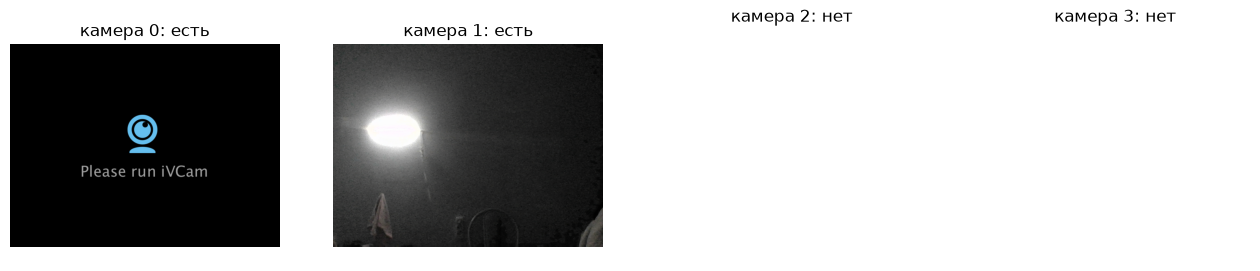

In [5]:
# Снимем по кадру с камер 0–3 и покажем их прямо в блокноте:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for i, ax in enumerate(axes):
    cap = cv2.VideoCapture(i, cv2.CAP_DSHOW)
    ok, frame = cap.read()
    cap.release()
    ax.set_title(f"камера {i}: {'есть' if ok else 'нет'}")
    ax.axis("off")
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))   # OpenCV хранит BGR, matplotlib ждёт RGB
plt.show()

In [11]:
import cv2

CAMERA = 1

cap = cv2.VideoCapture(CAMERA)
print("Камера открыта:", cap.isOpened())

ok, frame = cap.read()
print("Кадр получен:", ok, "| размер:", frame.shape if ok else None)
cap.release()

Камера открыта: True
Кадр получен: True | размер: (480, 640, 3)


In [12]:
# показывает картинку; закрыть: Esc (кликнув по окну) или крестик окна

cap = cv2.VideoCapture(CAMERA)
try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        cv2.imshow("camera", frame)

        key = cv2.waitKey(1) & 0xFF
        if key == 27:                                                   # Esc
            break
        if cv2.getWindowProperty("camera", cv2.WND_PROP_VISIBLE) < 1:   # нажали крестик
            break
finally:
    # выполнится ВСЕГДА — даже после Interrupt или ошибки
    cap.release()
    cv2.destroyAllWindows()


Что такое MediaPipe

Это бесплатная библиотека от Google с готовыми обученными моделями для камеры: лицо, руки, поза тела. Даём ей кадр, она возвращает координаты точек. Главное — Face Landmarker: около 470 точек на лице, включая веки и зрачки. Обучать её не нужно, она уже обучена, берём её выход как сырьё для своей модели.

Документация: ai.google.dev/edge/mediapipe. Нужный раздел — Solutions → Vision → Face Landmarker, там есть руководство для Python.

Тест: рисует точки лица прямо на видео с камеры, для проверки, видит ли MediaPipe моё лицо с нужного угла угла
Если сетка точек держится на лице, когда ты сидишь обычно, наклоняешься и щуришься, значит, угол подходит и можно двигаться дальше. Если сетка срывается, будем думать.

Скачать модель (один раз, ~4 МБ)
```
cd C:\Users\excavator\projects\cv\05_squint_lens
mkdir models
cd models
Invoke-WebRequest "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task" -OutFile face_landmarker.task
```

In [13]:
import time
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
vision = mp.tasks.vision

options = vision.FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="models/face_landmarker.task"),
    running_mode=vision.RunningMode.VIDEO,   # поток кадров с камеры
    num_faces=1,
)

cap = cv2.VideoCapture(CAMERA, cv2.CAP_DSHOW)
start = time.time()

try:
    with vision.FaceLandmarker.create_from_options(options) as landmarker:
        while True:
            ok, frame = cap.read()
            if not ok:
                break

            # mediapipe ждёт RGB, OpenCV даёт BGR
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)

            # в режиме VIDEO нужна метка времени в мс, и она должна расти
            ts = int((time.time() - start) * 1000)
            result = landmarker.detect_for_video(mp_image, ts)

            # рисуем точки: координаты приходят от 0 до 1, переводим в пиксели
            h, w = frame.shape[:2]
            for face in result.face_landmarks:
                for p in face:
                    cv2.circle(frame, (int(p.x * w), int(p.y * h)), 1, (0, 255, 0), -1)

            cv2.imshow("face", frame)
            if cv2.waitKey(1) & 0xFF == 27:
                break
            if cv2.getWindowProperty("face", cv2.WND_PROP_VISIBLE) < 1:
                break
finally:
    cap.release()
    cv2.destroyAllWindows()
